# Noise models and SNR measurement

The library includes the four noise models used in the paper, so that a denoiser can be tested on signals whose
clean version is known: white, pink, and brown noise, which are additive, and the quantization of an
analog-to-digital converter. This notebook adds each of them to a clean signal and measures the resulting
signal-to-noise ratio (SNR). No network is trained here.

In [1]:
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")     # quieter TensorFlow
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")    # these small networks train faster on the CPU
sys.path.insert(0, os.path.abspath(".."))              # use the library from this repository

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figstyle
import twn2n

figstyle.apply()

## 1. A clean signal

The clean signals are the impulse responses of the mass-spring-damper system with three degrees of freedom (3-DOF)
used in the paper. Each of the three records has six channels: the displacements and the accelerations of the three
masses.

In [2]:
from twn2n import benchmarks

system = benchmarks.three_dof_system()
t, clean = benchmarks.three_dof_impulse_responses(system)
print("natural frequencies (Hz):", np.round(system.fn, 2))
print("damping ratios:          ", np.round(system.zeta, 4))
print("records:", len(clean), "| shape of each record:", clean[0].shape, "| channels:", benchmarks.THREE_DOF_CHANNELS)

natural frequencies (Hz): [ 40.15 120.1  239.91]
damping ratios:           [0.01   0.0072 0.01  ]
records: 3 | shape of each record: (3072, 6) | channels: ('x1', 'x2', 'x3', 'a1', 'a2', 'a3')


## 2. Adding noise

`add_noise` corrupts every channel of every record with an independent sequence. For the additive models, the
standard deviation of the sequence follows from the requested SNR:

$$\sigma_{noise} = \frac{\sigma_{channel}}{10^{\mathrm{SNR}/20}}~.$$

The quantization model rounds each channel to the levels of an ideal converter. Its noise level is set by the
resolution (`bits`) and by the fraction of the input range that the signal occupies (`peak_fraction`), not by
`snr_db`.

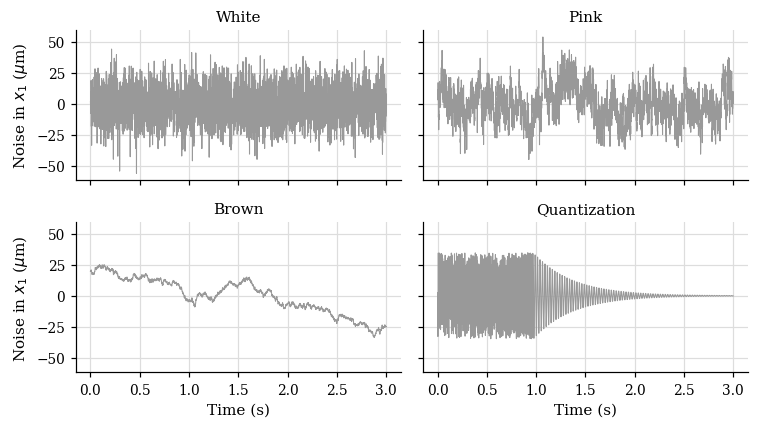

In [3]:
kinds = ["white", "pink", "brown", "quantization"]
noisy = {kind: twn2n.add_noise(clean, kind, snr_db=15.0, rng=0) for kind in kinds}

fig, axes = plt.subplots(2, 2, figsize=(7.0, 4.0), sharex=True, sharey=True)
for ax, kind in zip(axes.ravel(), kinds):
    ax.plot(t, 1e6 * (noisy[kind][0][:, 0] - clean[0][:, 0]), color=figstyle.COLORS["noisy"], linewidth=0.7)
    ax.set_title(f"{kind.capitalize()}")
for ax in axes[1]:
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Noise in $x_1$ ($\\mu$m)")
plt.tight_layout()
plt.show()

The four panels show the noise added to the displacement of the first mass (the difference between the noisy and
the clean signal). White noise has no memory. Pink noise and, more strongly, brown noise drift slowly. The
quantization error is not random: it is a function of the signal, bounded by half a level of the converter. The
next figure shows a part of the record in which the levels are visible. After about 1 s the response falls below
half a level, and the quantized signal is zero from then on.

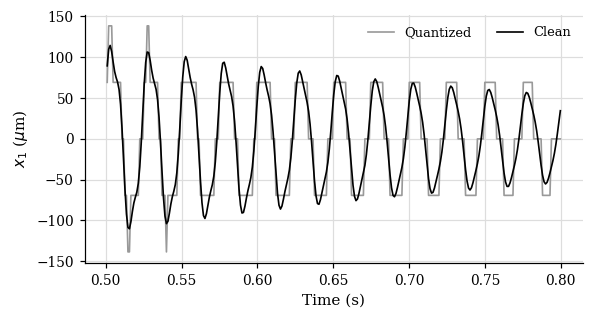

In [4]:
late = (t > 0.5) & (t < 0.8)
fig, ax = plt.subplots(figsize=(5.5, 3.0))
figstyle.line(ax, t[late], 1e6 * noisy["quantization"][0][late, 0], "noisy", label="Quantized")
figstyle.line(ax, t[late], 1e6 * clean[0][late, 0], "clean", linestyle="-")
ax.set_xlabel("Time (s)")
ax.set_ylabel("$x_1$ ($\\mu$m)")
ax.legend(ncol=2, loc="upper right")
plt.tight_layout()
plt.show()

## 3. Measuring the SNR

`snr_db` compares a signal with its clean reference. By default the selected channels are pooled into one value,
which is how the tables of the paper report the displacements. Pool only channels with the same physical unit.

In [5]:
displacements, accelerations = [0, 1, 2], [3, 4, 5]
rows = []
for kind in kinds:
    rows.append({"noise": kind,
                 "displacements (dB)": twn2n.snr_db(clean, noisy[kind], channels=displacements),
                 "accelerations (dB)": twn2n.snr_db(clean, noisy[kind], channels=accelerations)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

       noise  displacements (dB)  accelerations (dB)
       white               15.00               15.00
        pink               15.00               15.00
       brown               15.00               15.00
quantization               15.36               13.44


The three additive models give exactly the requested 15 dB. The quantization gives 15.36 dB for the displacements
with the default settings (12 bits, peak at 0.35% of the positive input range), the value reported in the paper.
A finer converter or a better use of its range gives a higher SNR:

In [6]:
for bits, fraction in [(12, 0.0035), (12, 0.035), (16, 0.0035)]:
    quantized = twn2n.quantize(clean, bits=bits, peak_fraction=fraction)
    print(f"{bits} bits, peak at {100 * fraction:.2f}% of the range: "
          f"{twn2n.snr_db(clean, quantized, channels=displacements):.2f} dB")

12 bits, peak at 0.35% of the range: 15.36 dB
12 bits, peak at 3.50% of the range: 33.12 dB
16 bits, peak at 0.35% of the range: 36.83 dB


## 4. What distinguishes the three additive models

The three models differ in how the noise power is distributed over frequency. The power spectral density of white
noise is flat, that of pink noise decays as $1/f$, and that of brown noise decays as $1/f^2$. The figure below
estimates the three densities from 200 sequences of each model.

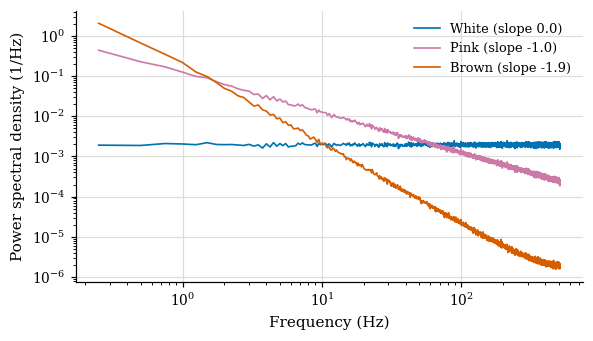

In [7]:
n = 4096
frequency = np.fft.rfftfreq(n, d=1 / system.fs)[1:]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for kind, color in zip(["white", "pink", "brown"], ["#0072B2", "#CC79A7", "#D55E00"]):
    spectra = [np.abs(np.fft.rfft(twn2n.colored_noise(kind, n, rng=seed))[1:]) ** 2 for seed in range(200)]
    density = np.mean(spectra, axis=0) / (n * system.fs / 2)
    band = (frequency > 5) & (frequency < 400)
    slope = np.polyfit(np.log10(frequency[band]), np.log10(density[band]), 1)[0]
    ax.loglog(frequency, density, color=color, label=f"{kind.capitalize()} (slope {slope:.1f})")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power spectral density (1/Hz)")
ax.legend()
plt.tight_layout()
plt.show()